# Exp1: Model comparison and historical source ablation

This notebook uses the shared evaluation engine to evaluate **nine unique models**. Six configurations compare model families, historical information, feature selection and demographic inclusion. Three additional configurations complete the five-group gradient-boosting source ablation. Application-only and all-sources gradient boosting are reused across both analyses rather than duplicated.

**Run All** to refresh the results. Seven models are trained from the feature table; the full gradient-boosting and demographic-variant predictions are loaded from the saved scores. The three source additions contain 10 bureau, 5 previous-application and 16 repayment features, respectively. Each is added separately to the same 120 application features. Gradient-boosting settings and shared splits remain fixed; gender and marital status are excluded from the source ablation and age is retained.

With `SAVE = True`, results replace `Exp_1/exp1_outputs/exp1_metrics.csv` (nine model rows) and `exp1_comparisons.csv` (eight contrasts × two metrics = sixteen rows). Holm correction covers all sixteen tests. Earlier trials are not appended, and intermediate prediction files are not exported.

For a quick comparison of only the two saved gradient-boosting variants, set `RUN_FINAL_COMPARISON = False`; quick mode displays results without overwriting the complete CSVs.

All models receive the shared core metrics, confidence intervals and paired tests. Supplementary top-5%/top-10% precision and recall and inline ROC/PR curves support review-capacity and source-contribution analysis.

In [1]:
import importlib.util
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT = next((parent for parent in (Path.cwd(), *Path.cwd().parents)
                if (parent / "Exp_1/exp1.ipynb").is_file()
                and (parent / "Exp_1/eval_exp1.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("Run from the project root or a folder inside bt4012_group6.")
HERE = PROJECT / "Exp_1"
OUTPUT = HERE / "exp1_outputs"
ENGINE = HERE / "eval_exp1.py"
spec = importlib.util.spec_from_file_location("shared_exp1_evaluation", ENGINE)
ev = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ev)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("Evaluator:", ENGINE)
print("Predictions:", OUTPUT)

Evaluator: /Users/yuran/Desktop/BT Group Project/bt4012_group6/outputs/outputs/exp1/eval_exp1.py
Predictions: /Users/yuran/Desktop/BT Group Project/bt4012_group6/Exp_1/exp1_outputs


## 1. Your models

In [2]:
RUN_FINAL_COMPARISON = True
N_BOOT = 1000
SAVE = True

In [3]:
def build_final_models(project, include_full=True):
    """Model family, five-source ablation, feature selection and demographics."""
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    output = project / "Exp_1/exp1_outputs"
    demographic = pd.read_csv(output / "sensitivity_scores.csv")
    best = pd.read_csv(output / "best_model_scores.csv")
    with_attributes = demographic[["SK_ID_CURR", "score_with_attributes"]].rename(
        columns={"score_with_attributes": "score"})
    saved = {"GBM all sources": best, "GBM all sources + demographics": with_attributes}
    if not include_full:
        return saved

    metadata = json.loads((output / "model_metadata.json").read_text())
    specification = metadata["sensitivity"]
    all_columns = specification["feature_sets"]["Without gender and marital status"]
    history = {c for cols in metadata["history_features"].values() for c in cols}
    application = [c for c in all_columns if c not in history]
    selected = metadata["selected_features"]
    assert len(history) == 31 and len(application) == 120
    assert set(selected).issubset(all_columns)
    features = pd.read_parquet(output / "features.parquet")
    split = pd.read_csv(project / "clean_data/splits.csv")[["SK_ID_CURR", "TARGET", "split"]]
    features = features.merge(split, on="SK_ID_CURR", validate="one_to_one")
    train = features["split"].eq("train")
    scored = features["split"].isin(["val", "test"])
    # Reuse the existing LR regularisation settings; do not tune on the test set.
    models = {
        "LR application": (application, make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(C=1.0, max_iter=2000))),
        "LR all sources": (all_columns, make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(C=0.1, max_iter=2000))),
        "GBM application": (application, HistGradientBoostingClassifier(
                              **specification["parameters"], **specification["fixed_settings"])),
        "GBM application + Bureau": (application + metadata["history_features"]["bureau"], HistGradientBoostingClassifier(
                              **specification["parameters"], **specification["fixed_settings"])),
        "GBM application + Previous": (application + metadata["history_features"]["previous"], HistGradientBoostingClassifier(
                              **specification["parameters"], **specification["fixed_settings"])),
        "GBM application + Repayment": (application + metadata["history_features"]["repayment"], HistGradientBoostingClassifier(
                              **specification["parameters"], **specification["fixed_settings"])),
        "GBM selected features": (selected, HistGradientBoostingClassifier(
                              **specification["parameters"], **specification["fixed_settings"])),
    }
    predictions = {}
    for label, (columns, model) in models.items():
        X = pd.get_dummies(features[columns], dummy_na=True).astype("float32")
        model.fit(X.loc[train], features.loc[train, "TARGET"])
        predictions[label] = features.loc[scored, ["SK_ID_CURR"]].assign(
            score=model.predict_proba(X.loc[scored])[:, 1])
        print(f"Trained {label}: {X.shape[1]} inputs; predictions kept in memory")
    return {
        "LR application": predictions["LR application"],
        "LR all sources": predictions["LR all sources"],
        "GBM application": predictions["GBM application"],
        "GBM application + Bureau": predictions["GBM application + Bureau"],
        "GBM application + Previous": predictions["GBM application + Previous"],
        "GBM application + Repayment": predictions["GBM application + Repayment"],
        "GBM all sources": best,
        "GBM selected features": predictions["GBM selected features"],
        "GBM all sources + demographics": with_attributes,
    }

def evaluate_final_models(engine, models, n_boot=1000):
    """Evaluate nine unique models and eight planned contrasts with the shared engine."""
    rows, evaluated = [], {}
    test_ids = set(engine.load_splits().query("split == 'test'")["SK_ID_CURR"])
    val_ids = set(engine.load_splits().query("split == 'val'")["SK_ID_CURR"])
    for label, values in models.items():
        frame = engine.load_predictions(values)
        if frame["SK_ID_CURR"].duplicated().any() or not np.isfinite(frame["score"]).all():
            raise ValueError(f"{label}: invalid or duplicate scores")
        val = frame[frame["split"].eq("val")].sort_values("SK_ID_CURR")
        test = frame[frame["split"].eq("test")].sort_values("SK_ID_CURR")
        if set(test["SK_ID_CURR"]) != test_ids or set(val["SK_ID_CURR"]) != val_ids:
            raise ValueError(f"{label}: must score every shared validation and test applicant")
        result = engine.evaluate(test.TARGET, test.score, y_val=val.TARGET, s_val=val.score, n_boot=n_boot)
        row = {"model": label, "threshold": result.attrs["threshold"]}
        for metric, values in result.iterrows():
            row[metric] = values["value"]
            row[metric + "_ci_low"] = values["ci_low"]
            row[metric + "_ci_high"] = values["ci_high"]
        if set(engine.SHOW) - set(result.index):
            raise ValueError("The final evaluator omitted a metric from the shared engine.")
        rows.append(row)
        evaluated[label] = {"val": val, "test": test, "threshold": result.attrs["threshold"]}
    pairs = [
        ("LR all sources", "LR application"),
        ("GBM all sources", "GBM application"),
        ("GBM application + Bureau", "GBM application"),
        ("GBM application + Previous", "GBM application"),
        ("GBM application + Repayment", "GBM application"),
        ("GBM all sources", "LR all sources"),
        ("GBM selected features", "GBM all sources"),
        ("GBM all sources + demographics", "GBM all sources"),
    ]
    comparisons = []
    for label, baseline in pairs:
        if label not in evaluated or baseline not in evaluated:
            continue
        trial, base = evaluated[label]["test"], evaluated[baseline]["test"]
        assert np.array_equal(trial.SK_ID_CURR, base.SK_ID_CURR)
        for metric in ("pr_auc", "roc_auc"):
            result = engine.compare_models(base.TARGET, trial.score, base.score, metric, n_boot)
            comparisons.append({"model": label, "vs_baseline": baseline, "metric": metric,
                "delta": result["delta"], "ci_low": result["ci_low"], "ci_high": result["ci_high"],
                "p_bootstrap": result["p_bootstrap"],
                "p_delong": result["delong_roc_auc"]["p_value"] if metric == "roc_auc" else np.nan})
    # Adjust across the complete set of planned tests, rather than separately by section.
    return pd.DataFrame(rows).set_index("model"), engine._add_p_values(pd.DataFrame(comparisons)), evaluated

QUEUE_METRICS = ["precision@top5%", "recall@top5%", "precision@top10%", "recall@top10%"]


def add_review_queue_metrics(table, evaluated, n_boot=1000, seed=42):
    """Supplement shared metrics with capacity-based review queues on test applicants."""
    result = table.copy()
    for label, prediction in evaluated.items():
        test = prediction["test"].sort_values("SK_ID_CURR")
        y = test["TARGET"].to_numpy(dtype=int)
        score = test["score"].to_numpy(dtype=float)
        ids = test["SK_ID_CURR"].to_numpy()

        def queue_values(index):
            # Higher scores first; applicant ID breaks score ties deterministically.
            order = np.lexsort((ids[index], -score[index]))
            ordered_y = y[index][order]
            positives = int(ordered_y.sum())
            values = {}
            for fraction, suffix in [(0.05, "5%"), (0.10, "10%")]:
                k = max(1, int(np.ceil(len(index) * fraction)))
                caught = int(ordered_y[:k].sum())
                values["precision@top" + suffix] = caught / k
                values["recall@top" + suffix] = caught / positives if positives else np.nan
            return values

        point = queue_values(np.arange(len(y)))
        rng = np.random.default_rng(seed)
        samples = []
        for _ in range(n_boot):
            index = rng.integers(0, len(y), len(y))
            if 0 < y[index].sum() < len(index):
                samples.append(queue_values(index))
        boot = pd.DataFrame(samples)
        for metric, value in point.items():
            result.loc[label, metric] = value
            result.loc[label, metric + "_ci_low"] = boot[metric].quantile(0.025)
            result.loc[label, metric + "_ci_high"] = boot[metric].quantile(0.975)
    return result


def display_ranking_curves(evaluated, labels=None):
    """Show ROC and precision-recall curves inline without extra output files."""
    import io
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from IPython.display import Image, display
    from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    # Four core configurations keep the main model-family comparison readable.
    labels = labels or [label for label in ["LR application", "LR all sources", "GBM application", "GBM all sources"]
              if label in evaluated]
    if not labels:
        labels = list(evaluated)
    for label in labels:
        test = evaluated[label]["test"]
        y, score = test["TARGET"], test["score"]
        fpr, tpr, _ = roc_curve(y, score)
        precision, recall, _ = precision_recall_curve(y, score)
        axes[0].plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(y, score):.3f})")
        axes[1].plot(recall, precision, label=f"{label} (AP {average_precision_score(y, score):.3f})")
    prevalence = evaluated[labels[0]]["test"]["TARGET"].mean()
    axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random ranking")
    axes[1].axhline(prevalence, color="black", linestyle="--", linewidth=1,
                    label=f"Test default rate ({prevalence:.3f})")
    axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Test ROC curves")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="Test precision-recall curves")
    for ax in axes:
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    fig.tight_layout()
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=140)
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


SOURCE_ABLATION_MODELS = [
    "GBM application", "GBM application + Bureau", "GBM application + Previous",
    "GBM application + Repayment", "GBM all sources",
]
MAIN_COMPARISON_MODELS = [
    "LR application", "LR all sources", "GBM application", "GBM all sources",
    "GBM selected features", "GBM all sources + demographics",
]


def display_source_ablation(engine, metrics, evaluated):
    labels = [label for label in SOURCE_ABLATION_MODELS if label in metrics.index]
    if len(labels) != 5:
        return
    print("Source contribution: identical gradient-boosting settings; application-only baseline")
    display(engine.pretty_metrics(metrics.loc[labels]))
    display(engine.pretty_metrics(metrics.loc[labels], metrics=QUEUE_METRICS))
    display_ranking_curves(evaluated, labels=labels)

MODELS = build_final_models(PROJECT, include_full=RUN_FINAL_COMPARISON)

Trained LR application: 250 inputs; predictions kept in memory
Trained LR all sources: 281 inputs; predictions kept in memory
Trained GBM application: 250 inputs; predictions kept in memory
Trained GBM application + Bureau: 260 inputs; predictions kept in memory
Trained GBM application + Previous: 255 inputs; predictions kept in memory
Trained GBM application + Repayment: 266 inputs; predictions kept in memory
Trained GBM selected features: 236 inputs; predictions kept in memory


## 2. Results

In [4]:
table, comps, preds = evaluate_final_models(ev, MODELS, n_boot=N_BOOT)
table = add_review_queue_metrics(table, preds, n_boot=N_BOOT)

### Test-set metrics
One row per model. Each cell shows **value (95% confidence interval)**. The threshold used for precision, recall and
F1 was chosen on the **validation** set (the value that maximises F1), so the test set stays untouched.

| Metric | Role | Meaning |
|---|---|---|
| `pr_auc` | **primary** | precision-recall area; the most informative with only ~8% defaulters (8% = random) |
| `roc_auc` | secondary | how well the model ranks defaulters above non-defaulters (0.5 = random, 1 = perfect); unaffected by the default rate, and the standard credit-scoring metric |
| `precision` / `recall` / `f1` | operating point | at the chosen threshold: share of flagged who default / share of defaulters flagged / balance of both |

Compare models on `pr_auc` and `roc_auc` (the significance tests below). Precision, recall and F1 depend on where each
model's threshold lands, so read them as one example operating point, not as the model comparison. The max-F1 threshold also
treats a missed defaulter and a wrongly flagged applicant as equally costly; a lender would normally set the cut-off
from the cost of each error and its review capacity.

**Evaluation definitions.** The shared engine supplies PR-AUC (average precision), ROC-AUC, validation-threshold precision/recall/F1, 1,000-resample bootstrap intervals, paired bootstrap tests for PR-AUC, DeLong tests for ROC-AUC and Holm-adjusted p-values. These definitions are unchanged.

**Supplement for the report.** Precision and recall among the top 5% and top 10% of test scores measure review capacity rather than the validation-selected max-F1 threshold. Queues contain `ceil(n_test × fraction)` applicants, with ties broken by applicant ID. Their 95% intervals use 1,000 paired-applicant bootstrap resamples, reranking within each resample. These are additional descriptive measures: the current shared evaluator no longer exports top-k metrics. They do not add tests to the ten-test Holm family.

In [5]:
main_labels = [label for label in MAIN_COMPARISON_MODELS if label in table.index]
print("Main model comparison — shared team metrics:")
display(ev.pretty_metrics(table.loc[main_labels]))
print("Main model comparison — supplementary review queues:")
display(ev.pretty_metrics(table.loc[main_labels], metrics=QUEUE_METRICS))

Main model comparison — shared team metrics:
Main model comparison — supplementary review queues:


,threshold,pr_auc,roc_auc,precision,recall,f1
model,,,,,,
LR application,0.148,0.205 (0.186-0.225),0.733 (0.718-0.746),0.212 (0.196-0.230),0.376 (0.349-0.404),0.271 (0.252-0.291)
LR all sources,0.158,0.224 (0.204-0.247),0.746 (0.731-0.760),0.237 (0.220-0.257),0.390 (0.364-0.417),0.295 (0.276-0.315)
GBM application,0.166,0.215 (0.196-0.237),0.741 (0.726-0.755),0.235 (0.217-0.254),0.350 (0.324-0.376),0.281 (0.260-0.301)
GBM all sources,0.144,0.250 (0.228-0.273),0.758 (0.743-0.772),0.230 (0.214-0.248),0.438 (0.410-0.467),0.302 (0.282-0.321)
GBM selected features,0.146,0.249 (0.228-0.272),0.758 (0.743-0.772),0.233 (0.216-0.251),0.433 (0.406-0.461),0.303 (0.283-0.323)
GBM all sources + demographics,0.126,0.248 (0.226-0.271),0.759 (0.744-0.772),0.217 (0.203-0.232),0.500 (0.472-0.528),0.302 (0.285-0.320)


,threshold,precision@top5%,recall@top5%,precision@top10%,recall@top10%
model,,,,,
LR application,0.148,0.289 (0.255-0.321),0.179 (0.160-0.198),0.240 (0.219-0.262),0.297 (0.274-0.320)
LR all sources,0.158,0.313 (0.280-0.347),0.194 (0.176-0.214),0.253 (0.231-0.276),0.313 (0.291-0.336)
GBM application,0.166,0.303 (0.267-0.333),0.187 (0.167-0.205),0.249 (0.226-0.269),0.308 (0.284-0.331)
GBM all sources,0.144,0.337 (0.305-0.371),0.209 (0.191-0.228),0.271 (0.249-0.294),0.335 (0.312-0.362)
GBM selected features,0.146,0.323 (0.289-0.356),0.200 (0.181-0.218),0.268 (0.247-0.291),0.332 (0.309-0.356)
GBM all sources + demographics,0.126,0.341 (0.309-0.375),0.211 (0.193-0.231),0.271 (0.249-0.293),0.335 (0.312-0.360)


### Planned comparisons and supporting questions

| Question | Model contrast |
|---|---|
| Does history help the linear model? | LR all sources versus LR application |
| Does history help the nonlinear model? | GBM all sources versus GBM application |
| What does bureau history add? | GBM application + Bureau versus GBM application |
| What do previous applications add? | GBM application + Previous versus GBM application |
| What does repayment behaviour add? | GBM application + Repayment versus GBM application |
| Does model family matter on identical inputs? | GBM all sources versus LR all sources |
| Does feature selection help? | GBM selected features versus GBM all sources |
| Do the two demographic attributes help? | GBM with demographics versus GBM all sources |

Each contrast is tested for PR-AUC and ROC-AUC. Positive differences favour the first model. The verdict uses Holm-adjusted p-values across all sixteen tests; confidence intervals are unadjusted. The all-sources-versus-application comparison also completes the source ablation and is not repeated.

In [6]:
display(ev.pretty_comparisons(comps))

,model,vs_baseline,metric,difference (95% CI),p_value,p_holm,verdict
0,LR all sources,LR application,pr_auc,+0.0198 (+0.0101 to +0.0300),0,0,significantly better
1,LR all sources,LR application,roc_auc,+0.0131 (+0.0070 to +0.0192),2.5e-05,0.00025,significantly better
2,GBM all sources,GBM application,pr_auc,+0.0351 (+0.0233 to +0.0455),0,0,significantly better
3,GBM all sources,GBM application,roc_auc,+0.0165 (+0.0106 to +0.0225),1.7e-07,1.9e-06,significantly better
4,GBM application + Bureau,GBM application,pr_auc,+0.0080 (+0.0013 to +0.0139),0.026,0.21,no significant difference
5,GBM application + Bureau,GBM application,roc_auc,+0.0021 (-0.0011 to +0.0052),0.23,1,no significant difference
6,GBM application + Previous,GBM application,pr_auc,+0.0067 (+0.0005 to +0.0125),0.038,0.27,no significant difference
7,GBM application + Previous,GBM application,roc_auc,+0.0019 (-0.0010 to +0.0048),0.23,1,no significant difference
8,GBM application + Repayment,GBM application,pr_auc,+0.0271 (+0.0170 to +0.0361),0,0,significantly better
9,GBM application + Repayment,GBM application,roc_auc,+0.0155 (+0.0104 to +0.0211),9e-09,1.1e-07,significantly better


### ROC/PR curves and source-contribution evidence

The first figure compares application-only and all-sources models within each family. The source-ablation tables and second figure then isolate the contribution of bureau, previous-application and repayment features under identical gradient-boosting settings. Both analyses are included in the same two CSV files without duplicate model rows.

Source contribution: identical gradient-boosting settings; application-only baseline


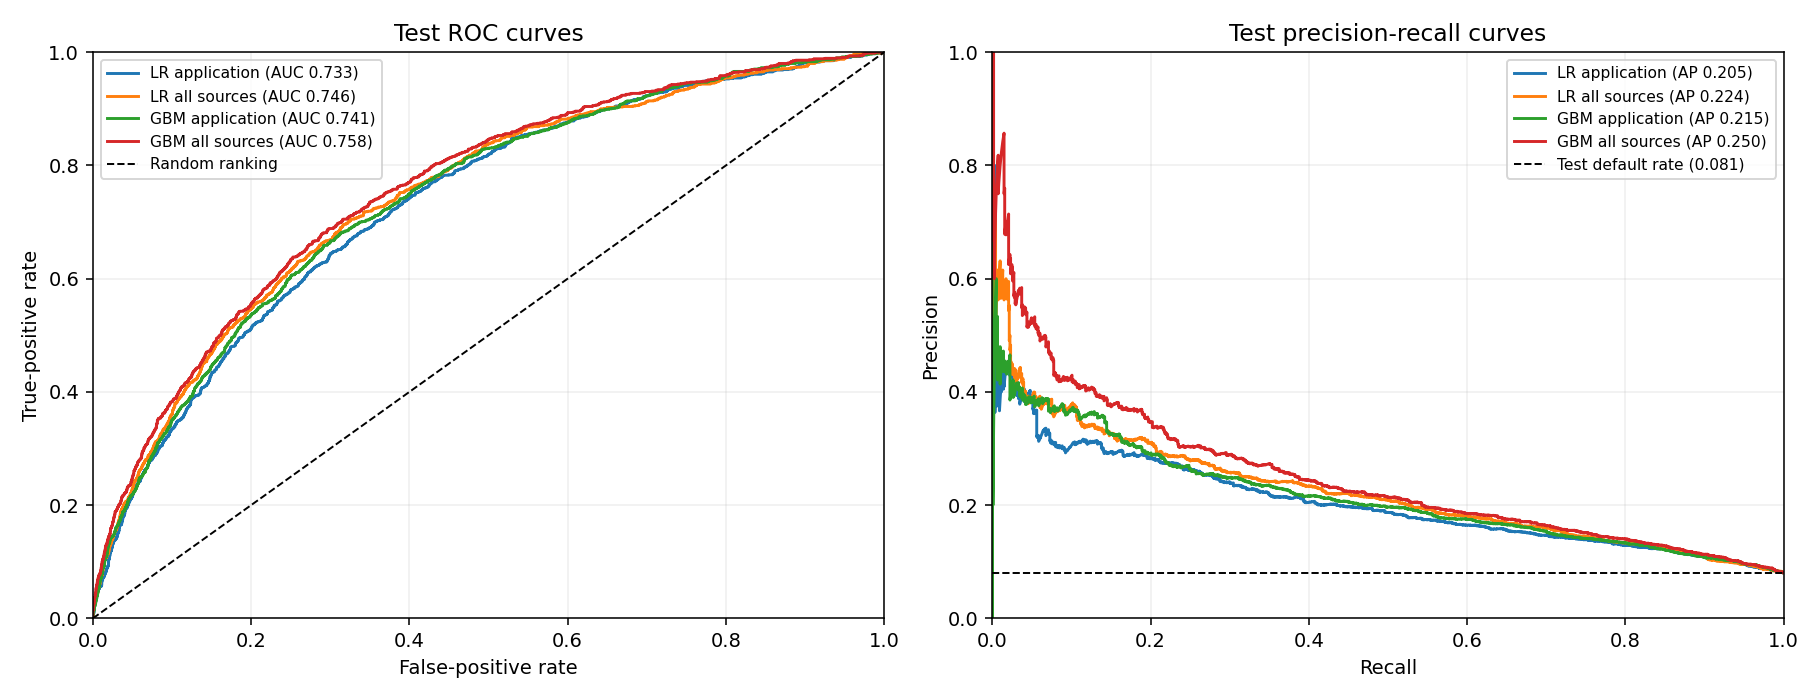

,threshold,pr_auc,roc_auc,precision,recall,f1
model,,,,,,
GBM application,0.166,0.215 (0.196-0.237),0.741 (0.726-0.755),0.235 (0.217-0.254),0.350 (0.324-0.376),0.281 (0.260-0.301)
GBM application + Bureau,0.157,0.223 (0.204-0.245),0.743 (0.728-0.757),0.229 (0.212-0.246),0.381 (0.355-0.406),0.286 (0.267-0.305)
GBM application + Previous,0.150,0.222 (0.202-0.243),0.743 (0.728-0.757),0.221 (0.204-0.238),0.391 (0.364-0.419),0.282 (0.264-0.302)
GBM application + Repayment,0.145,0.242 (0.221-0.265),0.757 (0.742-0.771),0.230 (0.213-0.247),0.433 (0.406-0.459),0.300 (0.281-0.319)
GBM all sources,0.144,0.250 (0.228-0.273),0.758 (0.743-0.772),0.230 (0.214-0.248),0.438 (0.410-0.467),0.302 (0.282-0.321)


,threshold,precision@top5%,recall@top5%,precision@top10%,recall@top10%
model,,,,,
GBM application,0.166,0.303 (0.267-0.333),0.187 (0.167-0.205),0.249 (0.226-0.269),0.308 (0.284-0.331)
GBM application + Bureau,0.157,0.304 (0.271-0.336),0.188 (0.169-0.209),0.247 (0.227-0.268),0.306 (0.285-0.328)
GBM application + Previous,0.150,0.297 (0.263-0.328),0.184 (0.164-0.202),0.248 (0.227-0.269),0.307 (0.285-0.332)
GBM application + Repayment,0.145,0.357 (0.320-0.391),0.221 (0.201-0.240),0.259 (0.239-0.281),0.321 (0.299-0.345)
GBM all sources,0.144,0.337 (0.305-0.371),0.209 (0.191-0.228),0.271 (0.249-0.294),0.335 (0.312-0.362)


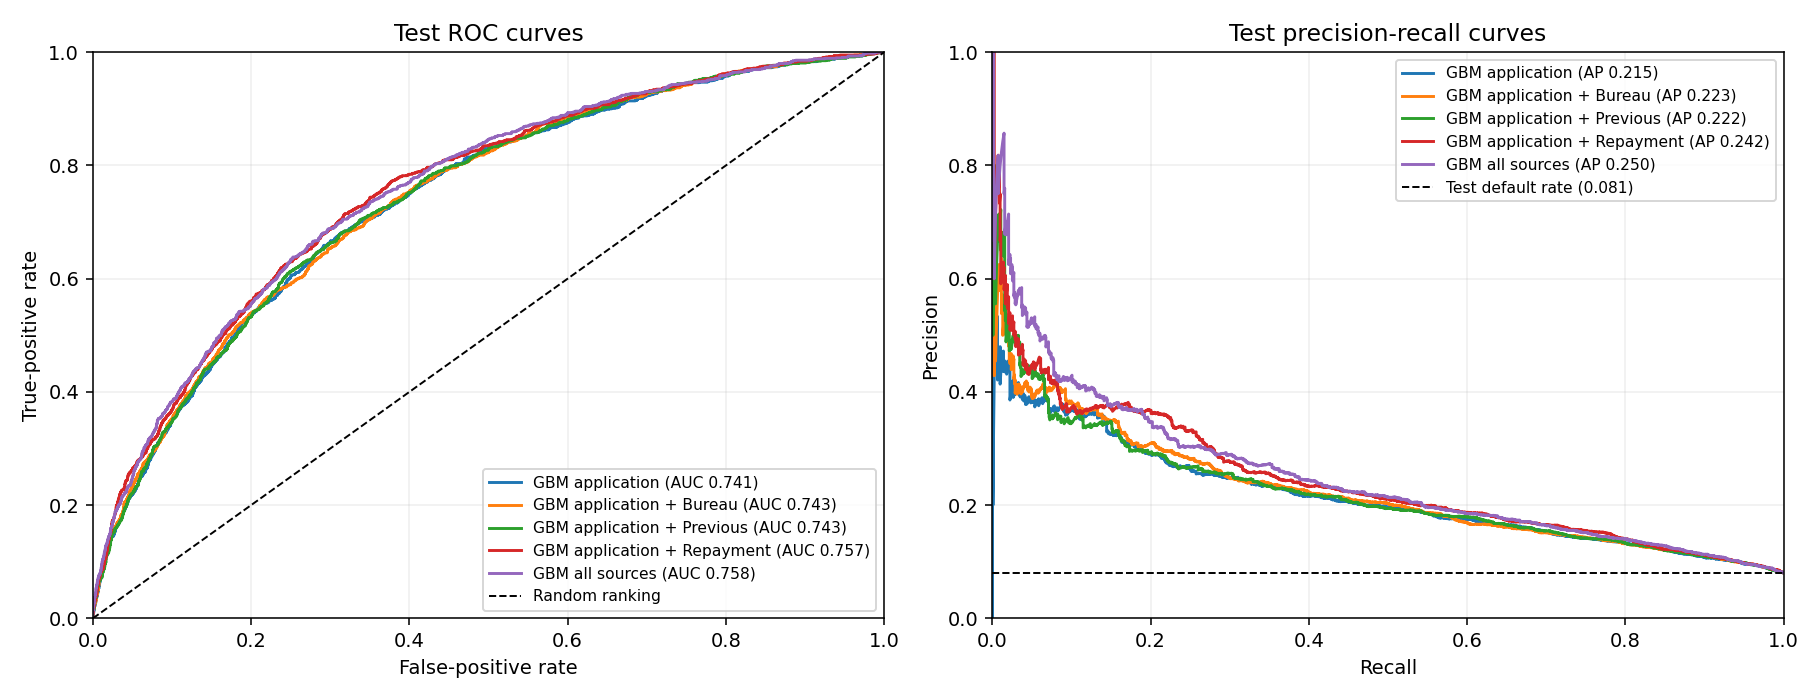

In [7]:
display_ranking_curves(preds)
display_source_ablation(ev, table, preds)

## 3. Save the complete comparison

Only the full nine-model comparison replaces the CSVs. Quick mode is display-only.

In [8]:
if SAVE and RUN_FINAL_COMPARISON:
    table.to_csv(OUTPUT / "exp1_metrics.csv")
    comps.to_csv(OUTPUT / "exp1_comparisons.csv", index=False)
    print("Saved:", OUTPUT / "exp1_metrics.csv", "and", OUTPUT / "exp1_comparisons.csv")
else:
    print("Results displayed only; final CSVs unchanged.")

Saved: /Users/yuran/Desktop/BT Group Project/bt4012_group6/Exp_1/exp1_outputs/exp1_metrics.csv and /Users/yuran/Desktop/BT Group Project/bt4012_group6/Exp_1/exp1_outputs/exp1_comparisons.csv
